# Задание 46. Полиномиальная регрессия с Lasso и Ridge

## 1. Что предсказываем

Берём 3000 вымышленных учебных сессий RemI AI из промежуточной аттестации. По числу правильных начальных ответов по уравнениям и производным прогнозируем долю правильных ответов на дополнительной проверке по производным. В проверке три вопроса, поэтому возможны доли 0, ⅓, ⅔ и 1.

Таблица лежит рядом с блокнотом. Для запуска нужны pandas, matplotlib и scikit-learn.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

data_path = Path("diagnostic_data.csv")
if not data_path.is_file():
    data_path = Path("cleaned.csv")

data = pd.read_csv(data_path).rename(columns={
    "initial_equations_correct": "Уравнения",
    "initial_derivatives_correct": "Производные",
})
target = "Доля правильных ответов"
data[target] = data["followup_correct"] / data["followup_count"]

print(f"Учебных сессий: {len(data)}")
data[["Уравнения", "Производные", target]].head()

Учебных сессий: 3000


,Уравнения,Производные,Доля правильных ответов
0,2,2,0.333333
1,1,0,0.333333
2,1,1,0.666667
3,0,1,0.333333
4,2,0,0.333333


## 2. Точечные графики

Размер точки показывает, сколько сессий приходится на одну пару значений. Линия соединяет средние доли при 0, 1 и 2 правильных начальных ответах.

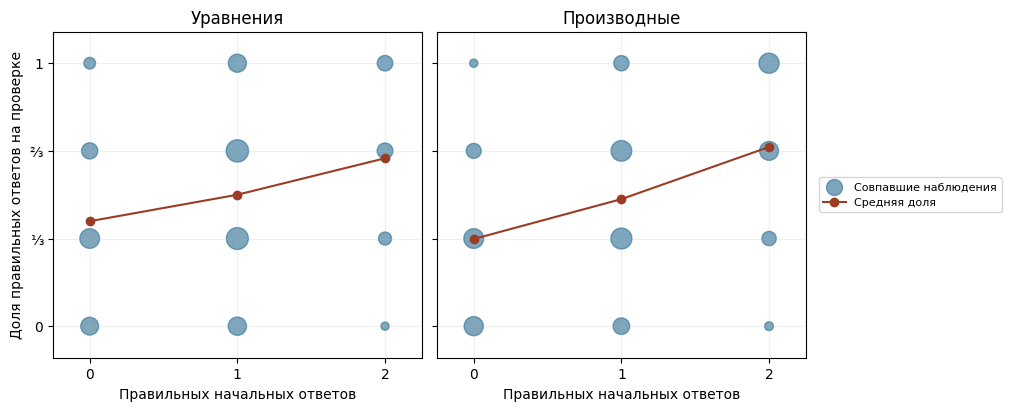

,Средняя доля по уравнениям,Средняя доля по производным
Правильных начальных ответов,,
0,0.399,0.331
1,0.500,0.483
2,0.639,0.681


In [2]:
features = ["Уравнения", "Производные"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True, layout="constrained")

for ax, feature in zip(axes, features):
    counts = data.groupby([feature, target]).size().reset_index(name="Сессий")
    averages = data.groupby(feature)[target].mean()
    ax.scatter(counts[feature], counts[target], s=counts["Сессий"] * 0.6,
               color="#37769a", alpha=0.65, label="Совпавшие наблюдения")
    ax.plot(averages.index, averages, "o-", color="#9b3c24", label="Средняя доля")
    ax.set_title(feature)
    ax.set_xlabel("Правильных начальных ответов")
    ax.set_xticks([0, 1, 2])
    ax.set_xlim(-0.25, 2.25)
    ax.set_yticks([0, 1/3, 2/3, 1], ["0", "⅓", "⅔", "1"])
    ax.set_ylim(-0.12, 1.12)
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Доля правильных ответов на проверке")
axes[1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=8)
plt.show()

data.groupby("Уравнения")[target].mean().rename("Средняя доля по уравнениям").round(3).to_frame().join(
    data.groupby("Производные")[target].mean().rename("Средняя доля по производным").round(3)
).rename_axis("Правильных начальных ответов")

По уравнениям средняя доля растёт с 0,40 до 0,64, по производным — с 0,33 до 0,68. В обоих случаях рост от одного до двух правильных ответов больше, чем от нуля до одного. Проверим, даёт ли добавление квадратов признаков более точный прогноз.

## 3. Разбиение и наборы признаков

Как в задании 45, оставляем 600 сессий для теста. Оставшиеся 2400 делим на обучение и проверочную выборку. По проверочной выборке выберем модель и значение `alpha` — силы штрафа за большие коэффициенты.

Сравним три набора: только производные, оба признака, оба признака вместе с их квадратами.

In [3]:
X = data[features].copy()
X["Уравнения²"] = X["Уравнения"] ** 2
X["Производные²"] = X["Производные"] ** 2
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42
)

specifications = {
    "Только производные": ["Производные"],
    "Оба признака": features,
    "Оба признака и квадраты": features + ["Уравнения²", "Производные²"],
}

print(f"Обучение: {len(X_fit)}, проверка: {len(X_val)}, тест: {len(X_test)}")

Обучение: 1800, проверка: 600, тест: 600


## 4. Масштабирование и обучение

Для каждого набора приводим признаки к сопоставимому масштабу через `StandardScaler`. Среднее и стандартное отклонение считаем на обучающей части. К проверочной применяем то же преобразование.

Lasso может обнулить отдельные коэффициенты. Ridge уменьшает их величину. Для каждой модели пробуем три значения `alpha`. Лучший вариант выбираем по наименьшей RMSE на проверочной выборке. Эта метрика сильнее учитывает большие ошибки.

In [4]:
model_types = {
    "Lasso": (Lasso, [0.001, 0.01, 0.1]),
    "Ridge": (Ridge, [0.1, 1.0, 10.0]),
}
results = []

for specification, columns in specifications.items():
    scaler = StandardScaler()
    fit_scaled = scaler.fit_transform(X_fit[columns])
    val_scaled = scaler.transform(X_val[columns])

    for name, (model_type, alphas) in model_types.items():
        for alpha in alphas:
            model = model_type(alpha=alpha)
            model.fit(fit_scaled, y_fit)
            prediction = model.predict(val_scaled)
            results.append({
                "Модель": name,
                "Признаки": specification,
                "alpha": alpha,
                "RMSE на проверке": mean_squared_error(y_val, prediction) ** 0.5,
            })

comparison = pd.DataFrame(results).sort_values("RMSE на проверке")
best = comparison.iloc[0]
display(comparison.reset_index(drop=True).round(8))
print(f'Выбрали {best["Модель"]}, {best["Признаки"].lower()}, alpha = {best["alpha"]:g}')

,Модель,Признаки,alpha,RMSE на проверке
0,Ridge,Оба признака и квадраты,0.100,0.321788
1,Ridge,Оба признака и квадраты,1.000,0.321788
2,Ridge,Оба признака и квадраты,10.000,0.321791
3,Lasso,Оба признака и квадраты,0.001,0.321862
4,Ridge,Оба признака,0.100,0.322066
5,Ridge,Оба признака,1.000,0.322069
6,Ridge,Оба признака,10.000,0.322101
7,Lasso,Оба признака,0.001,0.322141
8,Lasso,Оба признака и квадраты,0.010,0.322767
9,Lasso,Оба признака,0.010,0.323050


Выбрали Ridge, оба признака и квадраты, alpha = 0.1


## 5. Прогноз на тесте

Переобучаем выбранный вариант на всех 2400 обучающих сессиях и проверяем его на 600 отложенных сессиях. Для сравнения повторяем обычную линейную регрессию с двумя признаками из задания 45. Обе модели проверяем на одних и тех же сессиях.

MAE показывает среднюю абсолютную ошибку, RMSE сильнее учитывает большие отклонения. Чем меньше обе ошибки, тем лучше. R² показывает, насколько меньше сумма квадратов ошибок по сравнению с прогнозом средним значением на тесте.

In [5]:
best_columns = specifications[best["Признаки"]]
best_type, _ = model_types[best["Модель"]]

scaler = StandardScaler()
train_scaled = scaler.fit_transform(X_train[best_columns])
test_scaled = scaler.transform(X_test[best_columns])

model = best_type(alpha=best["alpha"])
model.fit(train_scaled, y_train)
baseline = LinearRegression().fit(X_train[features], y_train)

predictions = pd.DataFrame({
    "Факт": y_test,
    "Выбранная модель": model.predict(test_scaled),
    "Линейная модель из задания 45": baseline.predict(X_test[features]),
})
display(predictions.head().round(3))

metrics = []
for name in predictions.columns.drop("Факт"):
    predicted = predictions[name]
    metrics.append({
        "Модель": name,
        "MAE": mean_absolute_error(y_test, predicted),
        "RMSE": mean_squared_error(y_test, predicted) ** 0.5,
        "R²": r2_score(y_test, predicted),
    })

pd.DataFrame(metrics).set_index("Модель").round(5)

,Факт,Выбранная модель,Линейная модель из задания 45
1801,0.667,0.486,0.505
1190,0.667,0.486,0.505
1817,0.333,0.418,0.427
251,0.333,0.486,0.505
2505,1.000,0.747,0.733


,MAE,RMSE,R²
Модель,,,
Выбранная модель,0.25626,0.30647,0.24071
Линейная модель из задания 45,0.25704,0.30696,0.23827


## 6. Что получилось

По проверочной выборке выиграл Ridge с двумя признаками и их квадратами при `alpha = 0.1`. Соседние значения `alpha` дали почти ту же ошибку.

На тесте RMSE снизилась с 0,30696 до 0,30647 по сравнению с линейной моделью из задания 45. Разница меньше 0,05 процентного пункта. MAE выбранной модели около 0,256. В среднем прогноз отличается от фактической доли примерно на 26 процентных пунктов.

Для этого набора добавление квадратов и регуляризации почти не изменило качество прогноза дополнительной проверки. Результат относится к смоделированным сессиям RemI AI.